# Time series, baselines and exponential smoothing

After this block you can describe a time series by its trend, seasonality and autocorrelation, build a regular monthly series from count data with pandas, and produce baseline forecasts that every model must beat. You can fit an exponential smoothing model and report its forecast with a prediction interval, and you know where ARIMA fits in. The running question: how busy is Airbnb in Berlin, month by month, and what will the next year look like?

*Session 12, block 1. Course material, licence CC BY 4.0, with sections adapted from the third-party notebooks in [extras/](extras/README.md) (attribution at each section). Data: Inside Airbnb, Berlin, snapshot of 26 June 2026, and daily Berlin weather from Open-Meteo (both CC BY 4.0), prepared with `uv run python case-study/prepare_airbnb.py`.*

## Teaching map

The **core path** is what the lecturer teaches live in 45 minutes. Sections marked *(depth: self-study or if time allows)* go further; skip them in class and point students to them for self-study.

| Section | Minutes (core) | What it delivers |
|---|---|---|
| 1 · Time series: trend, seasonality, autocorrelation | 10 | The monthly review series, its STL decomposition and its ACF. Depth: STL parameters, robust weights, seasonal plots |
| 2 · Aggregating to regular time intervals | 7 | `resample`, partial and empty periods, survivorship, mean vs sum. Depth: the pandas date and time toolkit (`date_range`, periods, offsets, `asfreq`, `shift`, `rolling`) |
| 3 · Baselines | 8 | Naive, seasonal naive, moving average, MAE on a hold-out year. Depth: drift and mean methods, equivalent-date baselines, an interval for a baseline |
| 4 · Exponential smoothing with prediction intervals | 11 | SES by hand, ETS on the log counts, a 95 % interval and its coverage. Depth: α, Holt's variants, Holt–Winters, the state-space form, simulated paths |
| 5 · ARIMA as an outlook | 4 | The airline model, which can skip the pandemic months. Depth: ARIMA notation, stationarity tests, PACF, `STLForecast`, the long data format |
| Worked example · the pandemic months | 5 | Keep, cut or mark as missing: one comparison table |
| **Total core** | **45** | |

```mermaid
flowchart LR
    E["Count table<br/>(listing x month)"] --> A["One regular<br/>monthly series"]
    A --> P["Describe:<br/>trend, season, ACF"]
    P --> B["Baselines"]
    B --> M["Exponential smoothing,<br/>ARIMA"]
    M --> V["Compare on the<br/>hold-out year"]
```

In [1]:
# Run the code from the repository root, where the case-study paths start.
import os
from pathlib import Path

os.chdir(next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "case-study").is_dir()))

Next we import the libraries of this block. `statsmodels` provides the time series models; `warnings.filterwarnings("ignore")` hides its convergence notes, which would clutter the output.

In [2]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.exponential_smoothing.ets import ETSModel
from statsmodels.tsa.holtwinters import ExponentialSmoothing, Holt, SimpleExpSmoothing
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.statespace.sarimax import SARIMAX

warnings.filterwarnings("ignore")
pd.set_option("display.width", 140)
DATA = Path("case-study/data/airbnb")

## 1 · Time series: trend, seasonality and autocorrelation

A **time series** is a sequence of values measured at regular points in time: customers per day, sales per month, reviews per month. Think of a café. Over the years it gets more customers (the **trend**). Every weekend it is busier than on weekdays (the **seasonality**, a pattern that repeats with a fixed **period** m: m = 7 days for a weekly cycle, m = 12 months for a yearly one). And some days are just odd (the **remainder**).

The components can add up (y = trend + seasonal + remainder) or multiply (y = trend × seasonal × remainder). Multiplicative fits when the seasonal swings grow with the level: a café with twice the customers has a weekend peak twice as large. Taking the logarithm turns a product into a sum, so on the log scale a multiplicative series becomes additive.

Our series is demand for short-term rentals in Berlin, measured by the number of Airbnb guest reviews per month. Reviews are a **proxy** for stays: not every guest writes one, and the share who do can change, but it is the closest public measure.

Next we build the series. The case-study table `reviews_monthly` has one row per listing and month; `groupby("month")["n_reviews"].sum()` adds up all listings. We keep January 2016 to May 2026 (section 2 explains why the series stops there) and set the frequency to `"MS"`, monthly, dated at the month start.

125 months; {Timestamp('2019-07-01 00:00:00'): 4865, Timestamp('2020-04-01 00:00:00'): 285, Timestamp('2025-07-01 00:00:00'): 13132}


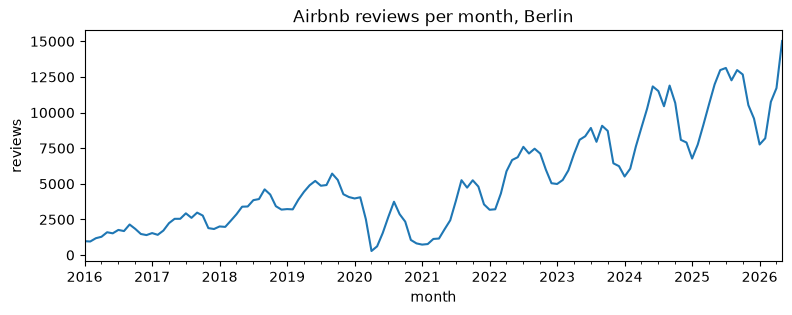

In [3]:
reviews = pd.read_parquet(DATA / "reviews_monthly.parquet")      # listing_id, month, n_reviews
y = reviews.groupby("month")["n_reviews"].sum()["2016":"2026-05"].rename("reviews")
y.index.freq = "MS"
print(len(y), "months;", y.loc[["2019-07-01", "2020-04-01", "2025-07-01"]].to_dict())
ax = y.plot(figsize=(9, 3), title="Airbnb reviews per month, Berlin")
ax.set_ylabel("reviews");

Three features are visible at once: strong growth (July 2019 against July 2025 in the printed values), a summer peak every year, and a collapse during the COVID-19 pandemic in spring 2020, when tourist stays were banned, with a slow recovery until late 2021.

**STL** (seasonal–trend decomposition using LOESS, a local smoothing method; Cleveland et al., 1990) estimates the three components. With `robust=True` it gives little weight to extreme months, so the pandemic does not distort the seasonal pattern; `seasonal=13` keeps the seasonal pattern fairly stable from year to year (section 1.1 explains the choice). We decompose the **log** counts, because the summer peak grows with the level.

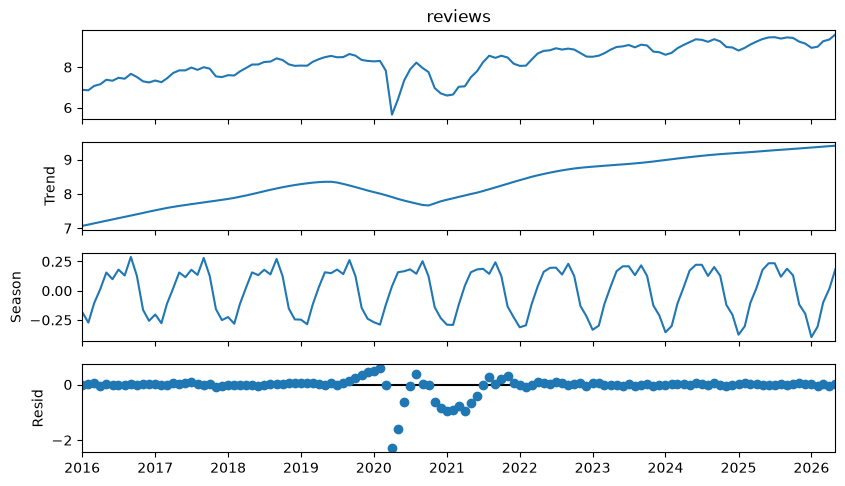

In [4]:
log_y = np.log(y)
stl = STL(log_y, period=12, seasonal=13, robust=True).fit()      # trend + seasonal + resid = log_y
stl.plot().set_size_inches(9, 5)

The seasonal panel is on the log scale. Next we turn it back into factors with `np.exp`: a factor of 1.2 means 20 % above the trend. We average the factors of each calendar month over 2022–2025 with `groupby(index.month)`.

In [5]:
recent = stl.seasonal["2022":"2025"]
factors = np.exp(recent).groupby(recent.index.month).mean()
factors.round(2).rename("seasonal factor").to_frame().T

month,1,2,3,4,5,6,7,8,9,10,11,12
seasonal factor,0.71,0.74,0.89,1.03,1.18,1.24,1.24,1.14,1.23,1.14,0.88,0.81


The summer months are about a quarter above the trend, January and February about a quarter to 30 % below. The decomposition says *that* January is low, not *why*: Berlin's tourist season is a plausible reading, but the data alone cannot show the cause.

### 1.1 · STL in more depth *(depth: self-study or if time allows)*

*Adapted from [STL decomposition](extras/01-stl-decomposition.ipynb) (statsmodels developers, BSD-3-Clause); applied to the Berlin review series.*

STL repeats two LOESS smoothings: one across the same month of different years (the seasonal smoother) and one along the deseasonalised series (the trend smoother). Its key inputs are:

- `period`: the length of the cycle, 12 for monthly data. Needed when the series has no frequency.
- `seasonal`: the length of the seasonal smoother, in years for monthly data. It must be odd. The default of 7 lets the seasonal pattern change slowly over time; a larger value forces a more stable pattern. Most applications should set it deliberately.
- `trend`: the length of the trend smoother, usually about 1.5 times the period; it must be odd and larger than `period`. statsmodels chooses it from `period` and `seasonal` when you leave it out.
- `low_pass`: the length of the low-pass filter, usually the smallest odd number larger than `period`.
- `robust`: a data-dependent weighting that downweights large remainders when estimating the LOESS.

Next we fit STL with and without robust weighting and compare the seasonal factor of April, the month of the deepest pandemic dip. `res.weights` holds the robustness weights, between 0 and 1.

April factor 2022-2025, robust: 1.03 | non-robust: 0.94


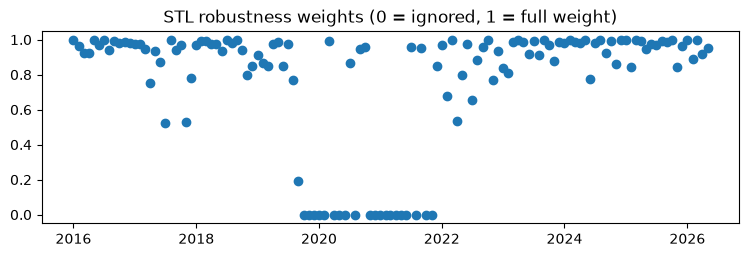

In [6]:
non_robust = STL(log_y, period=12, seasonal=13, robust=False).fit()
april = lambda res: np.exp(res.seasonal[res.seasonal.index.month == 4]["2022":]).mean()
print("April factor 2022-2025, robust:", round(april(stl), 2), "| non-robust:", round(april(non_robust), 2))
fig, ax = plt.subplots(figsize=(9, 2.5))
ax.plot(stl.weights, marker="o", linestyle="none")
ax.set_title("STL robustness weights (0 = ignored, 1 = full weight)");

The robust fit gives weight zero to many months between late 2019 and 2021: the pandemic months themselves and months next to the break, where a smooth trend cannot follow the sudden fall. It treats them as outliers instead of letting them pull the seasonal factors down. Without robust weighting, the pandemic leaks into the seasonal pattern of later years, as the lower April factor shows.

Next we see how the length of the seasonal smoother changes the seasonal component. `seasonal=7` (the default) lets the pattern drift from year to year; `seasonal=35` keeps it almost fixed.

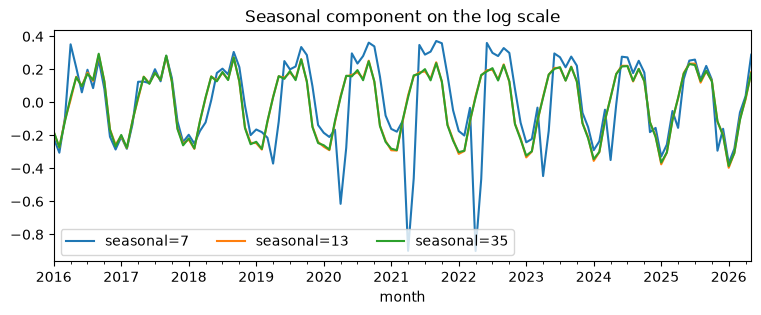

In [7]:
fig, ax = plt.subplots(figsize=(9, 3))
for s in (7, 13, 35):
    STL(log_y, period=12, seasonal=s, robust=True).fit().seasonal.plot(ax=ax, label=f"seasonal={s}")
ax.set_title("Seasonal component on the log scale")
ax.legend(ncol=3);

**A seasonal plot.** A second view of seasonality draws each year as one line over the twelve months. `pivot_table` with the year as columns and the month as rows does it in one step. The lines for 2020 and 2021 show the pandemic; the others share the summer shape at rising levels.

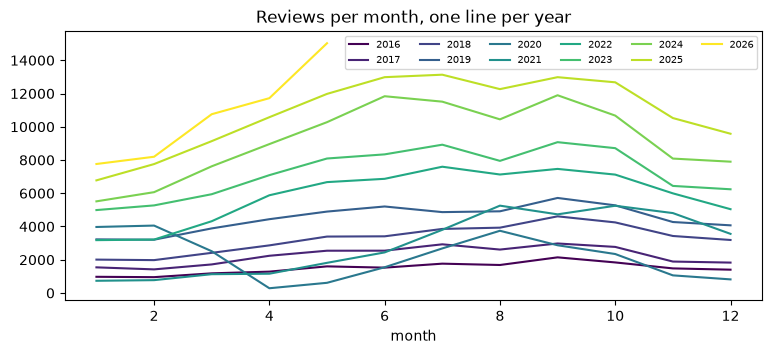

In [8]:
by_year = pd.DataFrame({"reviews": y.to_numpy(), "year": y.index.year, "month": y.index.month})
table = by_year.pivot_table(index="month", columns="year", values="reviews")
ax = table.plot(figsize=(9, 3.5), colormap="viridis", title="Reviews per month, one line per year")
ax.legend(ncol=6, fontsize=7);

**Autocorrelation.** Autocorrelation at lag k is the correlation between the series and itself shifted by k periods, corr(yₜ, yₜ₋ₖ). If it is warm today, it is probably warm tomorrow: today's value tells you something about the next one. The **autocorrelation function** (ACF) lists it for k = 1, 2, … . A trend alone makes it large: in the series 2, 4, 6, 8 the pairs (2, 4), (4, 6), (6, 8) lie on a perfect line. To see the season, remove the trend first by **differencing** (yₜ − yₜ₋₁); on log counts the difference is roughly the monthly growth rate. The shaded band in the plot is a rough 95 % range for a series without autocorrelation.

**Predict before running:** on the log counts, will the ACF be high only at lag 12, or at every lag? And after differencing?

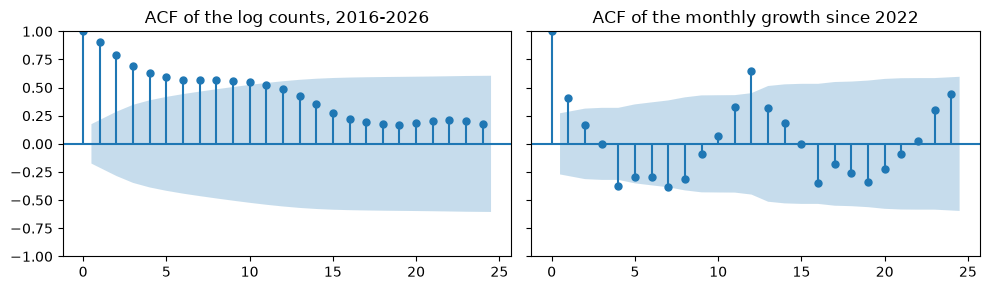

In [9]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3), sharey=True)
plot_acf(log_y, lags=24, ax=a1, title="ACF of the log counts, 2016-2026")
plot_acf(log_y["2022":].diff().dropna(), lags=24, ax=a2, title="ACF of the monthly growth since 2022")
plt.tight_layout()

On the log counts the ACF is high at every lag and decays slowly: that is the trend, not evidence of a season. After differencing the months since 2022, lag 12 stands out: the yearly pattern is strong compared with the month-to-month noise.

Autocorrelation is the reason time series need their own methods. Neighbouring months are not independent observations, so the random splits and ordinary cross-validation of Session 7 do not apply. Block 2 returns to this.

> **Note.** A trend makes the ACF look strong at every lag. High autocorrelations of a trending series are not evidence of seasonality or of a useful predictor. Difference first.

> **Note.** In practice, statistical offices publish seasonally adjusted figures computed with X-13ARIMA-SEATS or TRAMO/SEATS; Eurostat's 2020 guidance on the COVID-19 crisis recommended treating the lockdown months as outliers so that they would not change the seasonal factors, the same idea as robust STL.

> 📖 **Read more:** [extras/01-stl-decomposition.ipynb](extras/01-stl-decomposition.ipynb) (statsmodels examples): STL on the CO₂ series, the LOESS degree, the `*_jump` options that make STL fast on long series, and forecasting with `STLForecast`.

## 2 · Aggregating to regular time intervals with pandas

Forecasting methods expect one value per period at a fixed **frequency**. Event data (one row per review, order or call) become a series by counting or summing per period, like a shop that turns its till receipts into daily takings. In pandas the timestamps go into a `DatetimeIndex`, and `resample` groups them into calendar periods: `"D"` days, `"W"` weeks, `"MS"` months labelled by their first day, `"QS"` quarters, `"YS"` years. An aggregation (`size`, `sum`, `mean`) then gives one value per period.

The frequency is a modelling decision: it sets what can be forecast (a monthly staff plan needs monthly values), how noisy each value is, and which seasonal patterns are visible. Many forecasting errors start with a badly built series.

Next a tiny example: 3 and 5 reviews on 30 and 31 January, 2 and 4 on 1 and 3 February. `resample("MS").sum()` gives one total per month.

In [10]:
tiny = pd.Series([3, 5, 2, 4], index=pd.to_datetime(["2026-01-30", "2026-01-31", "2026-02-01", "2026-02-03"]))
tiny.resample("MS").sum()

2026-01-01    8
2026-02-01    6
Freq: MS, dtype: int64

**Predict before running:** the Airbnb snapshot was scraped between 26 June and 3 July 2026. What will the review totals of June and July 2026 look like? Next we print the last four months of the full series, before any cut.

In [11]:
full = reviews.groupby("month")["n_reviews"].sum()
full.tail(4)

month
2026-04-01    11720
2026-05-01    15024
2026-06-01     9968
2026-07-01       22
Name: n_reviews, dtype: int64

June 2026 has only part of its reviews and July almost none: the scrape stopped early in July. Keeping them would look like a collapse of demand. **The series must end with the last complete month**, May 2026.

A second, quieter problem: a review table only knows the listings that still existed on the scraping date. Listings that left Airbnb before June 2026 took their reviews with them, so the early years are undercounted by an unknown amount. Part of the growth since 2016 is an artefact of this **survivorship**.

A third problem appears for small series. Next we take one listing: months without reviews are *missing rows*, not zeros. `reindex` on the full monthly range with `fill_value=0` puts the empty months back.

In [12]:
one = reviews[reviews["listing_id"] == reviews["listing_id"].iloc[0]].set_index("month")["n_reviews"]
one = one["2016":"2026-05"]
dense = one.reindex(pd.date_range("2016-01-01", "2026-05-01", freq="MS"), fill_value=0)
print(len(one), "months with reviews out of", len(dense))
print("mean without empty months:", round(one.mean(), 2), "| true monthly mean:", round(dense.mean(), 2))

20 months with reviews out of 125
mean without empty months: 1.6 | true monthly mean: 0.26


Averaging only the months with reviews overstates this listing's monthly level several times over. For the city-wide sum it does not matter (every month has reviews); for a district or a single listing it does.

Finally a genuinely daily series. Open-Meteo provides the Berlin weather per day. Next we resample it to months. The aggregation must match the meaning of each column: the **mean** of the daily temperatures, but the **sum** of the daily rain. `.agg({...})` takes one function per column.

In [13]:
daily = pd.read_parquet(DATA / "weather_daily.parquet").set_index("date")
print(daily.columns.to_list())
monthly_wx = daily.resample("MS").agg({"temperature_2m_mean": "mean", "precipitation_sum": "sum"})
monthly_wx.loc["2025-06":"2025-09"].round(1)

['temperature_2m_mean', 'precipitation_sum', 'sunshine_hours']


,temperature_2m_mean,precipitation_sum
date,,
2025-06-01,19.7,48.6
2025-07-01,19.6,185.8
2025-08-01,18.9,40.4
2025-09-01,15.7,53.9


Block 2 asks whether these monthly weather values help the forecast.

> **Note.** Use `resample(...).size()` to count events and `.sum()` for amounts or pre-aggregated counts. Convert time zones with `tz_convert` before resampling to days.

### 2.1 · The pandas date and time toolkit *(depth: self-study or if time allows)*

*Code adapted from [Working with time series](extras/02-working-with-time-series.ipynb) (Jake VanderPlas, *Python Data Science Handbook*; code MIT, text CC BY-NC-ND 3.0): the code is MIT-licensed; the explanations here are our own, because the book's text may not be modified. Examples moved to the Berlin weather series.*

pandas builds its time tools on three kinds of objects. A **`Timestamp`** is one moment (like Python's `datetime`, but stored as a 64-bit NumPy `datetime64`); many of them form a `DatetimeIndex`. A **`Period`** is a whole interval, such as "March 2026"; many form a `PeriodIndex`. A **`Timedelta`** is a duration; many form a `TimedeltaIndex`. Our monthly series uses timestamps at the month start; a `Period` would say the same thing as an interval.

Next we parse dates from different string formats with `pd.to_datetime` and print the weekday with `strftime("%A")`. Adding a `Timedelta` array shifts a date by many amounts at once (vectorised, like NumPy).

In [14]:
date = pd.to_datetime("20th of May, 2026")          # the day the EU rental-data rules apply
print(date, date.strftime("%A"))
print(date + pd.to_timedelta(np.arange(3), "D"))
dates = pd.to_datetime(["2026-05-20", "21 May 2026", "2026/05/22"], format="mixed")
print(dates.to_period("D"))
print(dates - dates[0])                              # a TimedeltaIndex

2026-05-20 00:00:00 Wednesday
DatetimeIndex(['2026-05-20', '2026-05-21', '2026-05-22'], dtype='datetime64[us]', freq=None)
PeriodIndex(['2026-05-20', '2026-05-21', '2026-05-22'], dtype='period[D]')
TimedeltaIndex(['0 days', '1 days', '2 days'], dtype='timedelta64[us]', freq=None)


A `DatetimeIndex` makes slicing by date easy. A string such as `"2025"` selects a whole year; `"2025-06":"2025-08"` a range of months, both ends included. Next we use the daily weather.

In [15]:
temp = daily["temperature_2m_mean"]
print(temp["2025-06-01":"2025-06-03"].to_dict())
print("days in 2025:", len(temp["2025"]), "| mean summer 2025:", round(temp["2025-06":"2025-08"].mean(), 1), "°C")

{Timestamp('2025-06-01 00:00:00'): 20.5, Timestamp('2025-06-02 00:00:00'): 18.3, Timestamp('2025-06-03 00:00:00'): 19.1}
days in 2025: 365 | mean summer 2025: 19.4 °C


**Regular sequences.** `pd.date_range` builds a regular sequence of timestamps from a start and an end, or a start and a number of `periods`, with a frequency code `freq`. `pd.period_range` and `pd.timedelta_range` do the same for periods and durations. Frequencies can be combined (`"2h30min"`) and there are business-day variants (`"B"`, or the `BDay` offset object).

In [16]:
from pandas.tseries.offsets import BDay

print(pd.date_range("2026-06-01", periods=4, freq="MS"))
print(pd.period_range("2026-06", periods=4, freq="M"))
print(pd.timedelta_range(0, periods=3, freq="2h30min"))
print(pd.date_range("2026-05-29", periods=3, freq=BDay()))   # skips the weekend

DatetimeIndex(['2026-06-01', '2026-07-01', '2026-08-01', '2026-09-01'], dtype='datetime64[us]', freq='MS')
PeriodIndex(['2026-06', '2026-07', '2026-08', '2026-09'], dtype='period[M]')
TimedeltaIndex(['0 days 00:00:00', '0 days 02:30:00', '0 days 05:00:00'], dtype='timedelta64[ns]', freq='150min')
DatetimeIndex(['2026-05-29', '2026-06-01', '2026-06-02'], dtype='datetime64[us]', freq='B')


The most used **frequency codes** in current pandas (version 3 uses lower-case codes for hours and below):

| Code | Meaning | Code | Meaning |
|---|---|---|---|
| `D` | calendar day | `B` | business day |
| `W` | week (ending Sunday) | `W-MON` | week ending Monday |
| `MS` / `ME` | month start / month end | `BMS` / `BME` | business month start / end |
| `QS` / `QE` | quarter start / end | `YS` / `YE` | year start / end |
| `h`, `min`, `s` | hour, minute, second | `ms`, `us`, `ns` | milli-, micro-, nanosecond |

**`resample` against `asfreq`.** `resample` *aggregates* every value of a period; `asfreq` *selects* the value at each new time stamp. Next we compare both on the daily temperature: the monthly mean against the temperature on the first day of each month.

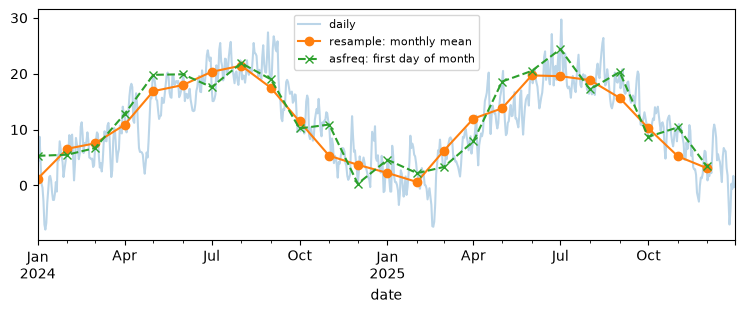

In [17]:
t = temp["2024":"2025"]
ax = t.plot(alpha=0.3, figsize=(9, 3), label="daily")
t.resample("MS").mean().plot(ax=ax, style="-o", label="resample: monthly mean")
t.asfreq("MS").plot(ax=ax, style="--x", label="asfreq: first day of month")
ax.legend(fontsize=8);

The `asfreq` line jumps around because it keeps one arbitrary day per month; the monthly mean is the useful summary. Going the other way, **upsampling** (for example monthly values to days) creates empty slots; `asfreq` with `ffill` copies the last value forward and `bfill` the next one backward.

In [18]:
monthly_mean = t.resample("MS").mean().iloc[:2]
print(monthly_mean.asfreq("D").head(3).to_dict())                  # NaN between the month starts
print(monthly_mean.asfreq("D", method="ffill").iloc[[0, 15, 31]].round(1).to_dict())

{Timestamp('2024-01-01 00:00:00'): 1.2129032258064514, Timestamp('2024-01-02 00:00:00'): nan, Timestamp('2024-01-03 00:00:00'): nan}
{Timestamp('2024-01-01 00:00:00'): 1.2, Timestamp('2024-01-16 00:00:00'): 1.2, Timestamp('2024-02-01 00:00:00'): 6.6}


**Shifting.** `shift(k)` moves the values k periods later along the index, so each row sees the value of k periods earlier. `y / y.shift(12) - 1` is the growth against the same month a year earlier, the most common comparison in business reporting and the basis of the lag features of block 2.

In [19]:
yoy = (y / y.shift(12) - 1).rename("growth against the same month a year earlier")
yoy["2025-01":"2025-06"].round(2).to_frame().T

month,2025-01-01,2025-02-01,2025-03-01,2025-04-01,2025-05-01,2025-06-01
growth against the same month a year earlier,0.23,0.28,0.2,0.18,0.17,0.1


**Rolling windows.** `rolling(n)` gives a window over the last n values, with the usual aggregations (`mean`, `median`, `sum`, `max`, or `agg`/`apply` for custom ones). `center=True` centres the window on each date, which is fine for describing the past but not for forecasting (it uses future values). A **Gaussian window** (`win_type="gaussian"`, with the width `std`) weights the centre more and gives a smoother line than the hard cut-off of a flat window.

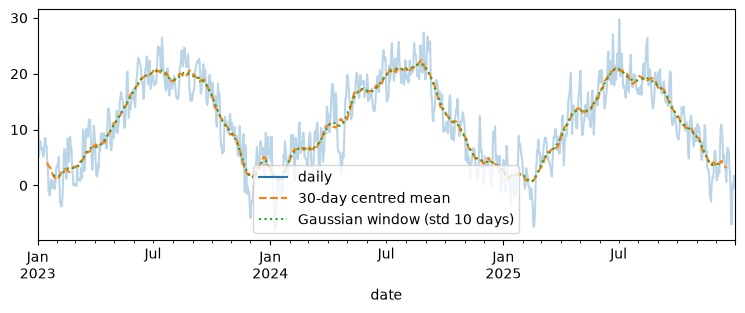

In [20]:
smooth = pd.DataFrame({
    "daily": temp["2023":"2025"],
    "30-day centred mean": temp["2023":"2025"].rolling(30, center=True).mean(),
    "Gaussian window (std 10 days)": temp["2023":"2025"].rolling(50, center=True, win_type="gaussian").mean(std=10),
})
ax = smooth.plot(figsize=(9, 3), style=["-", "--", ":"])
ax.lines[0].set_alpha(0.3)

**Grouping by a part of the date.** `groupby(index.month)` collects the same calendar month across years; `groupby(index.dayofweek)` the same weekday. Next we compute the **climate** of Berlin: the mean temperature and rain of each calendar month over all years. Block 2 uses it as the only honest weather "forecast" twelve months ahead.

In [21]:
climate = monthly_wx.groupby(monthly_wx.index.month).mean()
climate.round(1).T

date,1,2,3,4,5,6,7,8,9,10,11,12
temperature_2m_mean,1.4,2.6,5.4,9.5,14.6,19.7,19.9,20.3,16.3,11.2,5.6,3.1
precipitation_sum,55.6,49.9,40.2,32.5,41.4,69.6,75.6,47.3,40.5,54.5,45.7,49.8


> 📖 **Read more:** [extras/02-working-with-time-series.ipynb](extras/02-working-with-time-series.ipynb) (Python Data Science Handbook): dates in Python, NumPy and pandas side by side, the resolution limits of `datetime64`, and an analysis of hourly bicycle counts on a Seattle bridge by time of day and weekday. A reading copy: some of its code uses older pandas codes and a discontinued data source.

## 3 · Baselines: naive, seasonal naive and moving average

A **baseline** is a forecast so simple that any proposed model must beat it to be worth using. Weather forecasters compare themselves with "tomorrow will be like today"; a model that cannot beat that is useless. For a forecast h periods after the last observed value y_T:

- **Naive**: every future value equals the last observation, ŷ_{T+h} = y_T.
- **Seasonal naive**: every future value equals the value one season earlier. Next July equals last July.
- **Moving average**: the mean of the last n observations. It smooths noise but lags behind changes.
- **Seasonal naive × growth**: last year's value of the same month times the growth of the last twelve months over the twelve before. A rule anyone can compute in a spreadsheet.

If a model does not beat the baselines, either the approach has a problem or the extra complexity is not justified by the data.

We measure errors on a **hold-out period** at the end of the series, never used to fit: here the last twelve complete months, June 2025 to May 2026. The **mean absolute error** MAE = mean |yₜ − ŷₜ| is in the units of the series ("on average 1,000 reviews off per month").

Next we split the series and define `mae`. The split is by date, never random.

In [22]:
train, test = y[:"2025-05"], y["2025-06":]
h = len(test)


def mae(actual, forecast):
    return float(np.mean(np.abs(np.asarray(actual) - np.asarray(forecast))))


print(len(train), "training months;", h, "test months; test mean", round(test.mean()))

113 training months; 12 test months; test mean 11466


Next the four baselines, each a Series on the test months. `iloc[-12:]` takes the last twelve training months; `.to_numpy()` drops their dates so pandas does not try to align them with the test dates.

In [23]:
last_year = train.iloc[-12:].to_numpy()
growth = train.iloc[-12:].sum() / train.iloc[-24:-12].sum()
baselines = {
    "naive": pd.Series(train.iloc[-1], index=test.index),
    "seasonal naive": pd.Series(last_year, index=test.index),
    "moving average (3)": pd.Series(train.iloc[-3:].mean(), index=test.index),
    "seasonal naive x growth": pd.Series(last_year * growth, index=test.index),
}
print("growth of the last 12 months:", round(growth, 2))

growth of the last 12 months: 1.26


**Predict before running:** which baseline will have the smallest MAE on the hold-out year, and which the largest?

naive                      1710.0
seasonal naive             1586.0
moving average (3)         1935.0
seasonal naive x growth    1038.0
Name: MAE, dtype: float64

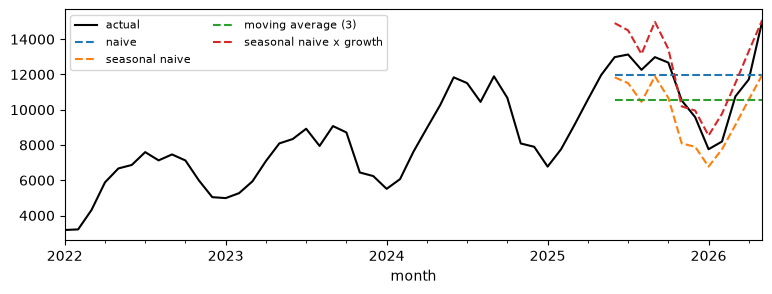

In [24]:
ax = y["2022":].plot(figsize=(9, 3), color="black", label="actual")
for name, fc in baselines.items():
    fc.plot(ax=ax, ls="--", label=name)
ax.legend(ncol=2, fontsize=8)
baseline_mae = pd.Series({name: mae(test, fc) for name, fc in baselines.items()}, name="MAE").round(0)
baseline_mae

The flat forecasts ignore the season. Plain seasonal naive follows the season but stays too low, because the market grew. Multiplying by last year's growth cuts the error clearly. This is the bar for every model in this session.

> **Note.** Never evaluate on random months. A random split puts later months into training and lets the model use the future to "predict" the past.

> **Note.** Avoid the percentage error (MAPE) for small counts: it divides by the actual value and explodes near zero, as for a single listing or April 2020.

### 3.1 · More baselines and an interval for a baseline *(depth: self-study or if time allows)*

*Adapted from [Baseline forecaster](extras/03-baseline-forecaster.ipynb) (skforecast developers, BSD-3-Clause); applied to the Berlin review series with plain pandas instead of skforecast.*

Two further classic baselines from *Forecasting: Principles and Practice* (FPP, Chapter 5):

- **Mean**: every future value equals the mean of the whole history. It ignores both trend and season.
- **Drift**: the naive forecast plus the average change per period, ŷ_{T+h} = y_T + h·(y_T − y₁)/(T − 1). Geometrically it extends the line from the first to the last observation.

skforecast generalises the naive family as **equivalent-date** forecasts: the forecast for a date is the value at the most recent "equivalent" date, `offset` steps back, aggregated over the last `n_offsets` equivalent dates with `agg_func`:

| Baseline strategy | `offset` | `n_offsets` | `agg_func` |
|---|---|---|---|
| Last observed value | 1 | 1 | none |
| Moving average (last k values) | 1 | k | mean |
| Seasonal naive (same period last season) | season length | 1 | none |
| Mean of the last k seasons | season length | k | mean or median |

One subtlety: within the forecast horizon these baselines do not roll forward. A "3-month moving average" is the mean of the last three *observed* values, repeated for every future month, not an average that updates with its own forecasts.

Next we write one small function for the equivalent-date family and evaluate a handful of configurations on the hold-out year, as skforecast's `grid_search_equivalent_date` does.

In [25]:
def equivalent_date(y_tr, index, offset, n_offsets, agg=np.mean):
    values = y_tr.to_numpy()
    out = []
    for step in range(1, len(index) + 1):
        # steps back from the forecast date to the equivalent dates inside the history
        k = int(np.ceil(step / offset)) * offset
        picks = [values[len(values) - k + step - 1 - j * offset] for j in range(n_offsets)]
        out.append(agg(picks))
    return pd.Series(out, index=index)


configs = {"last month": (1, 1), "3-month moving average": (1, 3), "same month last year": (12, 1),
           "mean of last 2 years": (12, 2), "mean of last 3 years": (12, 3)}
pd.Series({name: mae(test, equivalent_date(train, test.index, *c)) for name, c in configs.items()},
          name="hold-out MAE").round(0)

last month                1710.0
3-month moving average    1935.0
same month last year      1586.0
mean of last 2 years      2605.0
mean of last 3 years      3376.0
Name: hold-out MAE, dtype: float64

On a growing series, averaging over more years makes the seasonal baseline worse: older years were lower. That is why the growth-adjusted version above wins. Next the mean and drift methods for comparison.

In [26]:
T = len(train)
mean_fc = pd.Series(train.mean(), index=test.index)
drift_fc = pd.Series(train.iloc[-1] + np.arange(1, h + 1) * (train.iloc[-1] - train.iloc[0]) / (T - 1),
                     index=test.index)
print("mean MAE", round(mae(test, mean_fc)), "| drift MAE", round(mae(test, drift_fc)))

mean MAE 6912 | drift MAE 1908


**An interval for a baseline.** Baselines can have prediction intervals too. **Conformal prediction** builds them from past errors: compute the errors the method would have made in the past (its *residuals*), and add their empirical quantiles to the point forecast. If the past errors are representative of future ones, about 80 % of future values fall between the 10 % and 90 % quantiles.

Next we compute the in-sample errors of the seasonal naive × growth rule on the log scale for the months since 2023 (each month forecast from the year before it, so the pandemic years are not used), and turn their 10 % and 90 % quantiles into an 80 % interval for the hold-out year.

In [27]:
log_tr = np.log(train)
past_growth = (log_tr.rolling(12).sum() - log_tr.shift(12).rolling(12).sum()) / 12   # log growth of the last year
past_fc = log_tr.shift(12) + past_growth.shift(12)                                    # the rule, one year ahead
resid = (log_tr - past_fc)["2023":]
lo, hi = resid.quantile([0.1, 0.9])
band = pd.DataFrame({"lower": baselines["seasonal naive x growth"] * np.exp(lo),
                     "upper": baselines["seasonal naive x growth"] * np.exp(hi)})
inside = ((test >= band["lower"]) & (test <= band["upper"])).sum()
print(len(resid), "past errors; 80 % interval contains", inside, "of", h, "test months")

29 past errors; 80 % interval contains 11 of 12 test months


The log-scale growth here is the mean monthly log ratio, a close cousin of the ratio of yearly totals used above. With fewer than 30 past errors the quantiles are rough, but the idea scales to any model: block 2 uses backtest errors in the same way.

> 📖 **Read more:** [extras/03-baseline-forecaster.ipynb](extras/03-baseline-forecaster.ipynb) (skforecast): `ForecasterEquivalentDate` with calendar-aware offsets, conformal intervals, backtesting a baseline and searching over baseline configurations, on monthly fuel consumption in Spain. Needs its own environment (see the session README, Setup).

## 4 · Exponential smoothing with prediction intervals

The naive forecast trusts only the last value; a long moving average trusts all recent values equally. **Simple exponential smoothing** (SES) sits in between. Think of your opinion of a restaurant: each visit updates it, recent visits count more than old ones, but the old ones are not forgotten. SES keeps one number, the **level** ℓ, and updates it after each observation:

ℓₜ = α·yₜ + (1 − α)·ℓₜ₋₁, and the forecast for every future period is the last level.

The **smoothing parameter** α (between 0 and 1) sets how fast the level reacts. The weights on past values are α, α(1 − α), α(1 − α)², …: they decay exponentially, hence the name. α = 1 is the naive forecast.

Worked example with α = 0.5, the series 10, 12, 11, 15 and a starting level of 10: the levels are 10, 11, 11, 13, so the forecast is 13. Next we check this with statsmodels; `initialization_method="known"` fixes the starting level and `optimized=False` keeps our α.

In [28]:
tiny = pd.Series([10.0, 12.0, 11.0, 15.0])
ses = SimpleExpSmoothing(tiny, initialization_method="known", initial_level=10).fit(
    smoothing_level=0.5, optimized=False)
print(ses.level.to_list(), ses.forecast(2).to_list())

[10.0, 11.0, 11.0, 13.0] [13.0, 13.0]


Extensions add further smoothed components, each with its own parameter:

- **Holt's method** adds a **trend** b (the current slope, smoothing parameter β); the forecast is a straight line.
- A **damped trend** multiplies the slope by φ < 1 at each further step, so long-range forecasts flatten out instead of growing forever. A robust default for business series.
- **Holt–Winters** adds a **seasonal** component s with period m (smoothing parameter γ), added (additive) or multiplied (multiplicative).

The statistical form of these methods is the **ETS** model (Error, Trend, Seasonal). It estimates the parameters by maximum likelihood and, because it describes the errors, it also gives prediction intervals.

Next we fit ETS to the log counts: additive errors, a damped additive trend and additive seasonality (on the log scale, so multiplicative on the counts). Exponential smoothing has no notion of "this period was exceptional", so we fit it twice: on the whole history since 2016, and only on the months since January 2022, after the pandemic.

In [29]:
def fit_ets(y_tr, start):
    return ETSModel(np.log(y_tr[start:]), error="add", trend="add", damped_trend=True,
                    seasonal="add", seasonal_periods=12).fit(disp=False)


for start in ("2016", "2022"):
    model = fit_ets(train, start)
    params = dict(zip(model.param_names[:4], model.params[:4].round(3)))
    print(start, params, "MAE", round(mae(test, np.exp(model.forecast(h)))))

2016

 {'smoothing_level': 1.0, 'smoothing_trend': 0.0, 'smoothing_seasonal': 0.0, 'damping_trend': 0.98} MAE 1952
2022 {'smoothing_level': 0.175, 'smoothing_trend': 0.175, 'smoothing_seasonal': 0.0, 'damping_trend': 0.869} MAE 851


The choice of history decides the result. On the whole history the model sets α = 1 to follow the collapse and recovery: it becomes a seasonal version of the naive forecast and is worse than every sensible baseline. Fitted since 2022, a moderate α lets the level move, the trend is damped (φ below 1), and the MAE beats the best baseline. The cost is a short history of 41 months, which makes the estimates less certain.

**Prediction intervals.** A point forecast is one number; a **prediction interval** gives a range that should contain the future value with a stated probability, say 95 %. For SES with normal errors of standard deviation σ, the 95 % interval h steps ahead is ŷ ± 1.96·σ·√(1 + (h − 1)·α²): it widens with the horizon, because uncertainty about the level accumulates. It is not a confidence interval: a confidence interval is about a parameter (the mean number of reviews), a prediction interval about one future observation, so it is much wider. An interval is **calibrated** if about 95 % of future values fall inside; the share inside is its **coverage**.

Decisions depend on the range more than on the point: a cleaning company plans staff for a high but plausible summer, not for the average. Central banks publish "fan charts" for the same reason.

Next we compute the interval of the ETS model fitted since 2022. `get_prediction(...).summary_frame(alpha=0.05)` returns the columns `mean`, `pi_lower` and `pi_upper` on the log scale; `np.exp` takes them back to counts.

10 of 12 months inside the 95 % interval; outside: {Timestamp('2025-11-01 00:00:00'): 10524, Timestamp('2025-12-01 00:00:00'): 9580}


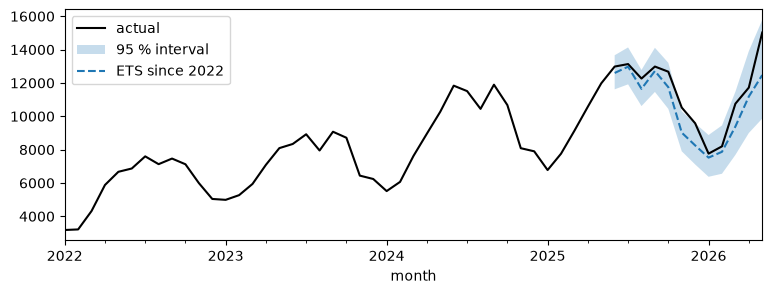

In [30]:
ets = fit_ets(train, "2022")
frame = np.exp(ets.get_prediction(start=test.index[0], end=test.index[-1]).summary_frame(alpha=0.05))
inside = (test >= frame["pi_lower"]) & (test <= frame["pi_upper"])
print(inside.sum(), "of", h, "months inside the 95 % interval; outside:", test[~inside].to_dict())
ax = y["2022":].plot(figsize=(9, 3), color="black", label="actual")
ax.fill_between(frame.index, frame["pi_lower"], frame["pi_upper"], alpha=0.25, label="95 % interval")
frame["mean"].plot(ax=ax, ls="--", label="ETS since 2022")
ax.legend(loc="upper left");

Next we look at how the width grows: the half-width of the interval as a share of the forecast, in the first and the last test month.

In [31]:
width = (frame["pi_upper"] - frame["pi_lower"]) / 2 / frame["mean"]
width.iloc[[0, -1]].round(2)

2025-06-01    0.08
2026-05-01    0.24
Freq: 11MS, dtype: float64

Most months fall inside; the two outside are winter months that were higher than the model thought plausible. The interval roughly triples in relative width over the year, and it is asymmetric on the count scale (the upper part is longer), which suits counts.

> **Note.** Model-based intervals assume the model is right and the future behaves like the past. A structural break is not in the interval. The EU regulation on short-term rental data (Regulation (EU) 2024/1028) applies from 20 May 2026; if enforcement removes unregistered Berlin listings, the series could drop in a way no interval here anticipates. Say what the interval does not include.

### 4.1 · The smoothing parameter α *(depth: self-study or if time allows)*

*Adapted from [Exponential smoothing](extras/04-exponential-smoothing.ipynb) (statsmodels developers, BSD-3-Clause); applied to the seasonally adjusted Berlin series.*

SES has no trend and no season, so we apply it to a series without season: the training months since 2022 divided by their STL seasonal factors (**seasonally adjusted**). We fit three variants: α fixed at 0.2, α fixed at 0.6, and α estimated by statsmodels (the recommended approach). `fittedvalues` are the one-step forecasts inside the training period.

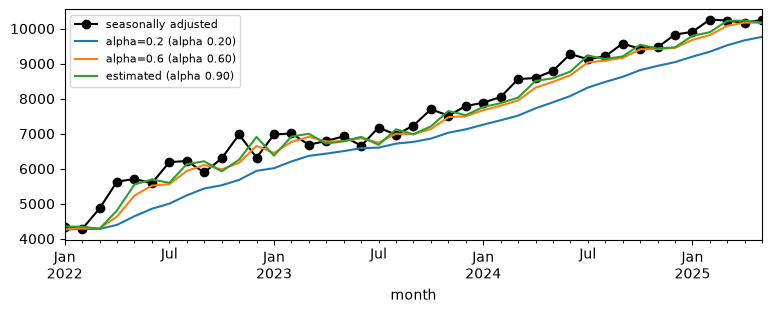

In [32]:
stl_tr = STL(np.log(train), period=12, seasonal=13, robust=True).fit()
sa = np.exp(np.log(train) - stl_tr.seasonal)["2022":].rename("seasonally adjusted")
fits = {f"alpha={a}": SimpleExpSmoothing(sa, initialization_method="heuristic").fit(smoothing_level=a, optimized=False)
        for a in (0.2, 0.6)}
fits["estimated"] = SimpleExpSmoothing(sa, initialization_method="estimated").fit()
ax = sa.plot(color="black", marker="o", figsize=(9, 3))
for name, fit in fits.items():
    fit.fittedvalues.plot(ax=ax, label=f"{name} (alpha {fit.params['smoothing_level']:.2f})")
ax.legend(fontsize=8);

A small α gives a smooth line that lags behind the growth; a large α follows every wiggle. The estimated α minimises the sum of squared one-step errors (SSE).

### 4.2 · Holt's trend variants *(depth: self-study or if time allows)*

*Adapted from [Exponential smoothing](extras/04-exponential-smoothing.ipynb) (statsmodels developers, BSD-3-Clause).*

Holt's method comes in three flavours: a **linear** trend (forecast is a straight line), an **exponential** trend (`exponential=True`, the slope is a growth factor, so the forecast curves upwards) and a **damped** trend (`damped_trend=True`, the slope fades by φ each step). Next we fit all three to the seasonally adjusted series and forecast 24 months, together with SES. The table collects the parameters and the SSE.

,SES,Holt linear,Holt exponential,Holt damped
alpha,0.902,0.529,0.424,0.508
beta,nan,0.000,0.424,0.000
phi,nan,nan,nan,0.985
l0,"4,347.652","4,253.682","4,264.592","4,262.770"
b0,nan,148.454,1.072,199.466
SSE (millions),4.811,3.245,3.854,3.163


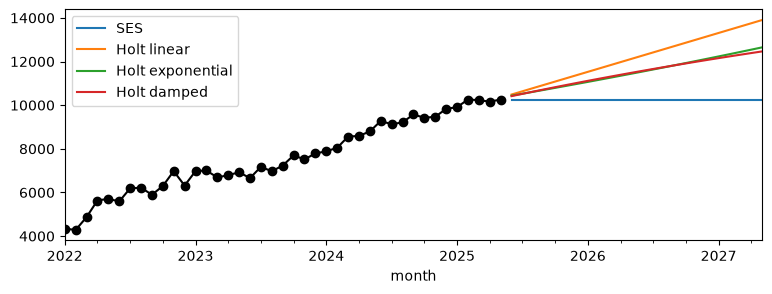

In [33]:
variants = {
    "SES": SimpleExpSmoothing(sa, initialization_method="estimated").fit(),
    "Holt linear": Holt(sa, initialization_method="estimated").fit(),
    "Holt exponential": Holt(sa, exponential=True, initialization_method="estimated").fit(),
    "Holt damped": Holt(sa, damped_trend=True, initialization_method="estimated").fit(),
}
ax = sa.plot(color="black", marker="o", figsize=(9, 3))
for name, fit in variants.items():
    fit.forecast(24).rename(name).plot(ax=ax, legend=True)
names = ["smoothing_level", "smoothing_trend", "damping_trend", "initial_level", "initial_trend"]
pd.DataFrame({n: [f.params.get(p, np.nan) for p in names] + [f.sse / 1e6] for n, f in variants.items()},
             index=["alpha", "beta", "phi", "l0", "b0", "SSE (millions)"]).map("{:,.3f}".format)

The three Holt models fit the past about equally well (SSE between about 3.2 and 3.9 million); SES fits worse because it ignores the growth and its forecast is flat. β is 0 for the linear and damped models, so their slope stays at its initial value while the level adapts. Yet the two-year forecasts differ: the linear trend extrapolates the growth of 2022–2025 furthest, the exponential and damped trends end lower. With φ ≈ 0.985 the damping is mild and shows only over longer horizons. The data cannot tell which is right; the choice is a judgement about the future. Damped trends have a strong record in forecasting competitions and empirical studies (Gardner, 2006, reviews the evidence), which is why they are a common default.

> **Note.** A non-damped trend extrapolates forever. Holt's linear trend fitted on a growth phase forecasts unlimited growth.

### 4.3 · Holt–Winters on the counts, and its internal states *(depth: self-study or if time allows)*

*Adapted from [Exponential smoothing](extras/04-exponential-smoothing.ipynb) (statsmodels developers, BSD-3-Clause).*

Instead of taking logs, Holt–Winters can model a multiplicative season directly (`seasonal="mul"`). Next we fit additive and multiplicative seasonality on the counts since 2022, both with a damped trend, and compare their parameters, SSE and hold-out MAE.

In [34]:
hw = {kind: ExponentialSmoothing(train["2022":], trend="add", damped_trend=True, seasonal=kind,
                                 seasonal_periods=12, initialization_method="estimated").fit()
      for kind in ("add", "mul")}
names = ["smoothing_level", "smoothing_trend", "damping_trend", "smoothing_seasonal"]
pd.DataFrame({f"seasonal={k}": [f.params[p] for p in names] + [f.sse / 1e6, mae(test, f.forecast(h))]
              for k, f in hw.items()}, index=["alpha", "beta", "phi", "gamma", "SSE (millions)", "hold-out MAE"]).map("{:,.3f}".format)

,seasonal=add,seasonal=mul
alpha,0.707,0.519
beta,0.000,0.000
phi,0.995,0.985
gamma,0.000,0.000
SSE (millions),6.197,3.667
hold-out MAE,602.046,504.973


The multiplicative season fits the training data better (lower SSE), as the growing summer peaks suggest. On this hold-out year both versions on the counts even beat the ETS model on the log counts of the core path; with γ = 0 the seasonal pattern is fixed in both. One hold-out year is one test, so block 2 compares models from several forecast origins.

The fitted model keeps its **states** over time: the level ℓₜ, the slope bₜ and the seasonal term sₜ. Plotting them shows what the model "believes" at each month. Next we plot the states of the multiplicative model; its seasonal state is a factor around 1.

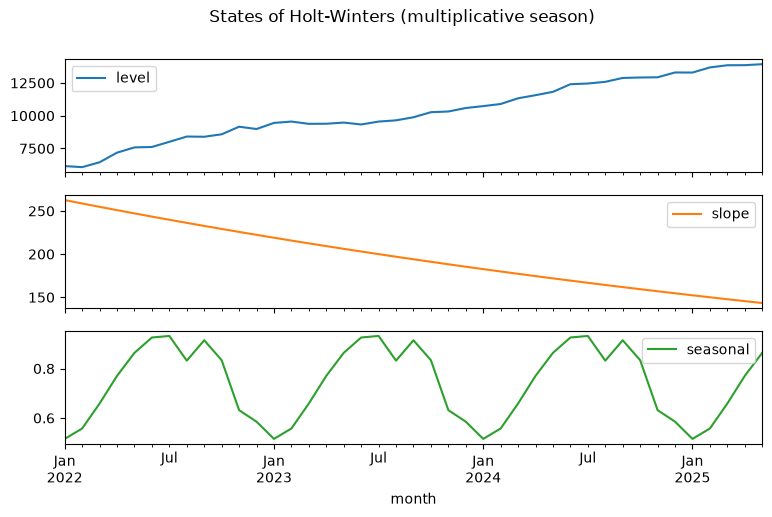

In [35]:
fit = hw["mul"]
states = pd.DataFrame({"level": fit.level, "slope": fit.trend, "seasonal": fit.season})
states.plot(subplots=True, figsize=(9, 5), title="States of Holt-Winters (multiplicative season)");

### 4.4 · ETS: the state-space form and simulated futures *(depth: self-study or if time allows)*

*Adapted from [ETS models](extras/05-ets-models.ipynb) (statsmodels developers, BSD-3-Clause).*

ETS models write exponential smoothing as a statistical model with an explicit error term eₜ. For SES, ETS(A, N, N) (additive error, no trend, no season):

- observation: yₜ = ℓₜ₋₁ + eₜ
- state update: ℓₜ = ℓₜ₋₁ + α·eₜ

Substituting eₜ = yₜ − ℓₜ₋₁ gives back the smoothing equation ℓₜ = α·yₜ + (1 − α)·ℓₜ₋₁, and the forecast ŷₜ|ₜ₋₁ = ℓₜ₋₁ is the previous level. For the additive Holt–Winters model, ETS(A, A, A):

- yₜ = ℓₜ₋₁ + bₜ₋₁ + sₜ₋ₘ + eₜ
- ℓₜ = ℓₜ₋₁ + bₜ₋₁ + α·eₜ
- bₜ = bₜ₋₁ + β·eₜ
- sₜ = sₜ₋ₘ + γ·eₜ

statsmodels' `ETSModel` implements all combinations of additive or multiplicative error, additive or multiplicative (possibly damped) trend, and additive or multiplicative season; not all of them are numerically stable. By default the initial states are estimated with the other parameters by maximum likelihood; `initialization_method="heuristic"` sets them from the first years instead. The model offers four prediction methods: `forecast` (out of sample), `predict` (in and out of sample), `get_prediction` (with intervals) and `simulate` (random future paths).

Next we print the summary of our ETS model fitted since 2022: parameters, initial states, log-likelihood and information criteria (AIC, BIC) for comparing ETS variants on the same data.

In [36]:
print(ets.summary().tables[1])
print("AIC", round(ets.aic, 1), "| BIC", round(ets.bic, 1))

                          coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------
smoothing_level         0.1746      0.280      0.623      0.533      -0.375       0.724
smoothing_trend         0.1745      0.089      1.970      0.049       0.001       0.348
smoothing_seasonal   8.254e-05        nan        nan        nan         nan         nan
damping_trend           0.8694      0.045     19.154      0.000       0.780       0.958
initial_level           7.9254        nan        nan        nan         nan         nan
initial_trend           0.1080      0.027      4.039      0.000       0.056       0.160
initial_seasonal.0      0.0954        nan        nan        nan         nan         nan
initial_seasonal.1      0.1869        nan        nan        nan         nan         nan
initial_seasonal.2      0.4540        nan        nan        nan         nan         nan
initial_seasonal.3      0.5370  

For some models the interval has an analytical formula; for the others, `get_prediction` **simulates** many future paths (1,000 by default) and takes their percentiles. We can draw such paths ourselves. Next we simulate 100 futures of 12 months from the end of the training data (`anchor="end"`) and plot them with the 95 % interval.

share of simulated values inside the analytic 95 % interval: 0.93


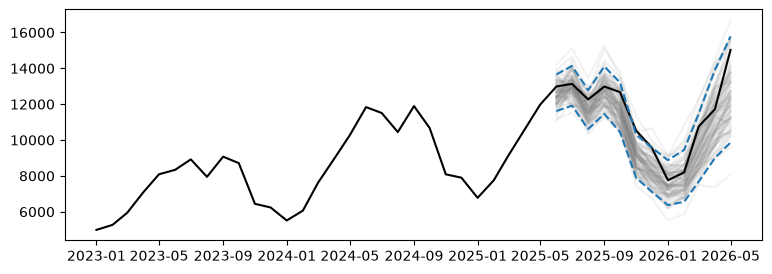

In [37]:
np.random.seed(0)                                     # reproducible random paths
paths = np.exp(ets.simulate(anchor="end", nsimulations=12, repetitions=100))
paths.index = test.index
fig, ax = plt.subplots(figsize=(9, 3))
ax.plot(paths.index, paths.to_numpy(), color="grey", alpha=0.1)
ax.plot(y["2023":].index, y["2023":], color="black", label="actual")
ax.plot(frame.index, frame[["pi_lower", "pi_upper"]].to_numpy(), "--", color="tab:blue")
print("share of simulated values inside the analytic 95 % interval:",
      round(((paths.T >= frame["pi_lower"]) & (paths.T <= frame["pi_upper"])).to_numpy().mean(), 2))

The cloud of simulated paths and the analytic interval agree: about 95 % of simulated values fall inside. Simulation is also how you get an interval for a *total*: the 12-month sum of each path gives a distribution of yearly totals, which is narrower than adding up the monthly interval limits.

> 📖 **Read more:** [extras/04-exponential-smoothing.ipynb](extras/04-exponential-smoothing.ipynb) (statsmodels examples): SES, Holt and Holt–Winters on the FPP example series, Box-Cox transformations and bootstrapped simulations. [extras/05-ets-models.ipynb](extras/05-ets-models.ipynb) (statsmodels examples): ETS models compared with R's `forecast` package, heuristic against estimated initial states, and `get_prediction` intervals.

## 5 · ARIMA as an outlook

**ARIMA** is the other classical family of forecasting models. It describes the autocorrelation directly: **I** (integrated) differences the series to remove the trend, **AR** (autoregressive) lets the differenced value depend on its own previous values, and **MA** (moving average) on previous forecast errors (not the moving-average baseline). **Seasonal ARIMA** adds the same terms at the seasonal lag. The classic **airline model**, written (0, 1, 1)(0, 1, 1)₁₂, was introduced by Box and Jenkins for airline passenger numbers: it differences once at lag 1 and once at lag 12 and has one MA term of each kind.

One practical advantage: statsmodels estimates ARIMA as a state-space model, which steps over **missing values**. A month set to `NaN` is predicted but not used to update the model. That gives a third way to handle the pandemic, besides keeping it or cutting the history.

Next we mark March 2020 to December 2021 as missing with `.where(~covid)` and fit the airline model with `SARIMAX`. `get_forecast(h)` returns the forecast and `conf_int` its 95 % interval.

In [38]:
covid = pd.Series((y.index >= "2020-03-01") & (y.index <= "2021-12-01"), index=y.index)


def fit_airline(y_tr, skip_covid=True):
    log_tr = np.log(y_tr).where(~covid[y_tr.index]) if skip_covid else np.log(y_tr)
    return SARIMAX(log_tr, order=(0, 1, 1), seasonal_order=(0, 1, 1, 12)).fit(disp=False)


fc = fit_airline(train).get_forecast(h)
airline, ci = np.exp(fc.predicted_mean), np.exp(fc.conf_int(alpha=0.05))
inside = ((test >= ci.iloc[:, 0]) & (test <= ci.iloc[:, 1])).sum()
print("airline MAE", round(mae(test, airline)), "|", inside, "of", h, "inside the interval")

airline MAE 450 | 12 of 12 inside the interval


With the pandemic marked as missing, the airline model has the lowest hold-out error so far. Marking months as missing is an assumption: it says the pandemic months tell us nothing about level, trend and season afterwards. Plausible for a ban on tourist stays, but it belongs in the report.

### 5.1 · ARIMA in more depth *(depth: self-study or if time allows)*

*Adapted from [ARIMA tutorial](extras/06-arima.ipynb) (statsmodels developers, BSD-3-Clause); applied to the Berlin review series.*

In formulas, with Δᵈ the difference operator applied d times, ARIMA(p, d, q) is

Δᵈyₜ = c + φ₁·Δᵈyₜ₋₁ + … + φₚ·Δᵈyₜ₋ₚ + θ₁·εₜ₋₁ + … + θ_q·εₜ₋_q + εₜ

- **p**, the autoregressive order: how many past values of the differenced series enter;
- **d**, the differencing order: how often to difference until the series is **stationary** (its mean and variance do not change over time);
- **q**, the moving-average order: how many past errors enter.

A standard recipe: choose d with a unit-root test, then read candidate p and q from the ACF and the **partial ACF** (PACF: the correlation at lag k after removing the effect of the shorter lags), start simple and compare candidates with an information criterion (AIC or BIC) and on a hold-out period.

The **augmented Dickey–Fuller (ADF) test** has the null hypothesis "the series has a unit root" (is not stationary); a small p-value suggests stationarity. Next we test the log counts since 2022, their first difference, and the series differenced at lag 1 and lag 12 (as the airline model does).

In [39]:
from statsmodels.tsa.stattools import adfuller

post = np.log(train["2022":])
for name, s in {"log counts": post, "first difference": post.diff(),
                "lag-1 and lag-12 difference": post.diff().diff(12)}.items():
    s = s.dropna()
    print(f"{name:28s} n={len(s):3d}  ADF p-value {adfuller(s, maxlag=3)[1]:.3f}")

log counts                   n= 41  ADF p-value 0.012
first difference             n= 40  ADF p-value 0.000
lag-1 and lag-12 difference  n= 28  ADF p-value 0.011


The test even rejects a unit root for the log counts, which plainly trend: with only 41 months (28 after seasonal differencing) and a strong season, the ADF test is unreliable, so treat it as a hint, not a verdict, and look at the plots. Next the ACF and PACF of the doubly differenced series. Spikes at lag 1 and lag 12 in the ACF point to the MA(1) and seasonal MA(1) terms of the airline model.

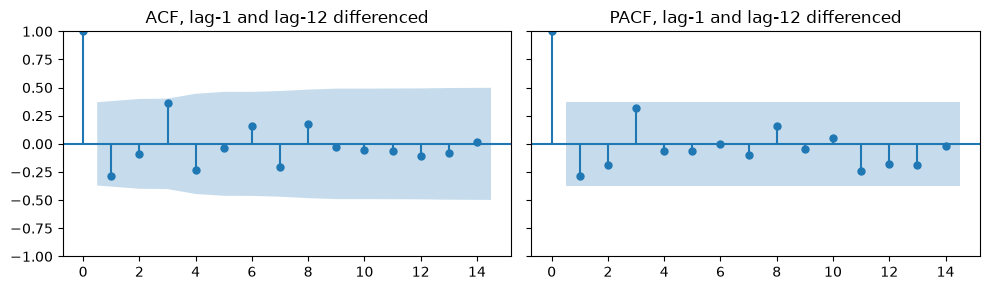

In [40]:
dd = post.diff().diff(12).dropna()
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3), sharey=True)
plot_acf(dd, lags=14, ax=a1, title="ACF, lag-1 and lag-12 differenced")
plot_pacf(dd, lags=14, ax=a2, title="PACF, lag-1 and lag-12 differenced", method="ywm")
plt.tight_layout()

Next we read the summary of the airline model fitted with the pandemic as missing. The middle table has the coefficients (`ma.L1` and `ma.S.L12`) with standard errors and p-values; `sigma2` is the error variance on the log scale. The bottom table has residual diagnostics: Ljung–Box tests for leftover autocorrelation, Jarque–Bera for normality and a test for changing variance.

In [41]:
airline_fit = fit_airline(train)
print(airline_fit.summary().tables[1])
print(airline_fit.summary().tables[2])

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1         -0.1969      0.101     -1.940      0.052      -0.396       0.002
ma.S.L12      -0.6248      0.106     -5.916      0.000      -0.832      -0.418
sigma2         0.0046      0.001      6.430      0.000       0.003       0.006
Ljung-Box (L1) (Q):                   1.29   Jarque-Bera (JB):                13.67
Prob(Q):                              0.26   Prob(JB):                         0.00
Heteroskedasticity (H):               0.82   Skew:                            -0.23
Prob(H) (two-sided):                  0.57   Kurtosis:                         4.75


**Common pitfalls** (adapted from the same tutorial):

- Not checking stationarity before choosing d. A wrong d gives misleading forecasts.
- A random train–test split instead of a split in time.
- Confusing the methods: `forecast` returns out-of-sample point forecasts; `predict` works in and out of sample for a given range; `get_forecast` and `get_prediction` return the richest output, including intervals.
- Overfitting with large p and q. Always check on a held-out period.
- ARIMA is linear and assumes the dynamics do not change: structural breaks need explicit treatment (missing values, dummies, a shorter history).

**Decomposition plus ARIMA.** `STLForecast` removes the season with STL, forecasts the seasonally adjusted series with any model, and adds the last seasonal cycle back. Next we combine STL with an ARIMA(1, 1, 0) with drift on the log counts since 2022.

In [42]:
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.forecasting.stl import STLForecast

stlf = STLForecast(np.log(train["2022":]), ARIMA, model_kwargs=dict(order=(1, 1, 0), trend="t"),
                   robust=True).fit()
print("STL + ARIMA(1,1,0) with drift, hold-out MAE:", round(mae(test, np.exp(stlf.forecast(h)))))

STL + ARIMA(1,1,0) with drift, hold-out MAE: 955


**The long data format.** Libraries that forecast many series at once, such as Nixtla's StatsForecast, expect a **long** table with three columns: `unique_id` (which series), `ds` (the date) and `y` (the value). Next we bring our series into that shape; the district series of the case study would simply be more `unique_id` values in the same table.

In [43]:
long = y.rename("y").rename_axis("ds").reset_index().assign(unique_id="berlin")[["unique_id", "ds", "y"]]
long.tail(3)

,unique_id,ds,y
122,berlin,2026-03-01,10755
123,berlin,2026-04-01,11720
124,berlin,2026-05-01,15024


*The long-format description is adapted from [StatsForecast quick start](extras/07-statsforecast-quickstart.ipynb) (Nixtla, Apache-2.0).* With that table, `StatsForecast(models=[AutoARIMA(season_length=12)], freq="MS")` would choose the ARIMA orders automatically by AIC and `predict(h=12, level=[95])` would return forecasts with intervals.

> 📖 **Read more:** [extras/06-arima.ipynb](extras/06-arima.ipynb) (statsmodels examples): ARIMA end to end on US real GDP, from the ADF test to the forecast plot. [extras/07-statsforecast-quickstart.ipynb](extras/07-statsforecast-quickstart.ipynb) (Nixtla StatsForecast): `AutoARIMA` with prediction intervals on the air passengers data; needs its own environment (see the session README, Setup).

## Worked example · How should we treat the pandemic months?

The practice question of this block: how busy is Airbnb in Berlin month by month, and how do we treat the pandemic? We have built the series, checked its quality and computed the baselines. Three treatments of the break remain:

- **keep** the months and let the model adapt to them;
- **cut** the history and start after the break (January 2022);
- **mark them as missing** and keep the years before and after.

Next we fit each treatment and collect the hold-out MAE and the coverage of the 95 % interval in one table. The helper `evaluate` takes a fitted statsmodels result (ETS or SARIMAX) and reads its forecast and interval from `summary_frame`, whose last two columns are the interval limits for both model types.

In [44]:
def evaluate(result):
    frame = np.exp(result.get_prediction(start=test.index[0], end=test.index[-1]).summary_frame(alpha=0.05))
    lower, upper = frame.iloc[:, -2], frame.iloc[:, -1]          # the last two columns are the limits
    inside = ((test >= lower) & (test <= upper)).sum()
    mean = frame["mean"]
    return {"MAE": round(mae(test, mean)), "months inside 95 %": int(inside)}


pd.DataFrame({
    "ETS, keep (since 2016)": evaluate(fit_ets(train, "2016")),
    "ETS, cut (since 2022)": evaluate(fit_ets(train, "2022")),
    "airline, keep": evaluate(fit_airline(train, skip_covid=False)),
    "airline, mark as missing": evaluate(fit_airline(train)),
}).T

,MAE,months inside 95 %
"ETS, keep (since 2016)",1952,12
"ETS, cut (since 2022)",851,10
"airline, keep",2122,12
"airline, mark as missing",450,12


How the break is handled matters more than the choice between ETS and ARIMA: both model families are worse than the spreadsheet baseline (seasonal naive × growth) when they keep the pandemic, and better when they cut it or skip it. On this hold-out year, the airline model with the pandemic marked as missing wins.

But one hold-out year is one test. A model can win a single year by luck. Block 2 repeats the comparison from six forecast origins (backtesting) and adds a machine-learning model.

## Check your understanding

1. Monthly reviews swing by ±1,000 at a level of 4,000 and by ±3,000 at a level of 12,000. Additive or multiplicative? Which transformation helps?
2. The ACF of the log counts is high at every lag. Does this show a yearly pattern? What should you compute instead?
3. Why must the series end in May 2026, and what would a naive forecast do if June 2026 were kept?
4. Why can the growth of the review series since 2016 be overstated?
5. ETS fitted on the whole history sets α = 1. What does that mean for its forecasts?

## Exercises (30 min)

Work in pairs. The lecturer picks which exercises to set; there are more than fit into 30 minutes. Answer *Paper*, *Predict* and *Class* tasks in the markdown cell below the task before running any code, *Code* tasks in the empty code cells. Stretch tasks are for pairs who finish early. The core cells above (series `y`, `train`, `test`, `covid`, `mae`, `fit_ets`, `fit_airline`) must have been run.

### 1.1 · Which chart is real?

*Class · 5 min*

> The lecturer shows four monthly series: one real series and three random walks. Vote: which one is real, and why do you think so?

*Source:* [Wickham et al. (2010), "Graphical inference for infovis", IEEE TVCG](https://doi.org/10.1109/TVCG.2010.161)

*Your answer:*

### 1.2 · Class forecast tournament

*Class · 15 min*

> The cell below prints 36 months of Berlin reviews, June 2022 to May 2025. Without a computer model, forecast the next three months (June, July and August 2025) by hand and write your three numbers down. The lecturer collects the forecasts and compares them with the actual values and with the seasonal naive forecast.

*Source:* original exercise for this course; background: [Hyndman & Athanasopoulos, *Forecasting: Principles and Practice* (3rd ed.), simple methods](https://otexts.com/fpp3/toolbox.html#sec-simple-methods)

In [45]:
s = y["2022-06":"2025-05"]
s.groupby([s.index.year.rename("year"), s.index.month.rename("month")]).sum().unstack().astype("Int64")

month,1,2,3,4,5,6,7,8,9,10,11,12
year,,,,,,,,,,,,
2022,<NA>,<NA>,<NA>,<NA>,<NA>,6868,7596,7128,7464,7122,5994,5041
2023,4988,5269,5942,7089,8090,8339,8921,7948,9073,8712,6441,6239
2024,5513,6065,7621,8957,10276,11837,11510,10445,11895,10672,8086,7899
2025,6775,7755,9135,10575,11977,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>


*Your answer:*

### 1.3 · Spurious correlation

*Code · 10 min*

> Generate two independent random walks of length 100 (`np.cumsum` of standard normal noise) and compute their correlation. Repeat 100 times. How often is |r| above 0.5? What happens if you correlate the differences (`np.diff`) instead?

*Source:* [Granger & Newbold (1974), "Spurious regressions in econometrics", *Journal of Econometrics*](https://doi.org/10.1016/0304-4076(74)90034-7)

### 1.4 · Exponential smoothing by hand

*Paper · 10 min*

> Simple exponential smoothing with α = 0.5 on the series 10, 14, 12, 16, starting the level at the first value. Compute the level after each value and the forecast for the next period.

*Source:* [*Forecasting: Principles and Practice*, simple exponential smoothing](https://otexts.com/fpp3/exponential-smoothing.html#sec-ses)

*Your answer:*

### 1.5 · January against February

*Class · 5 min*

> February has fewer reviews than March. Is that lower demand or a shorter month? How would you check it with `y`?

*Source:* [*Forecasting: Principles and Practice*, calendar adjustments](https://otexts.com/fpp3/decomposition.html#sec-transformations)

*Your answer:*

### 1.6 · How much history for ETS?

*Code · 15 min*

> The notebook fits ETS (additive error, damped additive trend, additive seasonality, on the log counts) on `train` from January 2022 with `fit_ets(train, "2022")`. Fit the same model from July 2021 and from January 2023. For each start, compute the MAE on `test`, the width of the 95 % prediction interval in the first and the last month (as a share of the forecast; `get_prediction(...).summary_frame(alpha=0.05)`, back-transformed with `np.exp`) and the number of months inside the interval. What does this tell you about the reliability of a model fitted on a short history?

*Source:* original exercise for this course; background: [*Forecasting: Principles and Practice*, ETS models](https://otexts.com/fpp3/ets.html)

### 1.7 · A lockdown dummy

*Code · 15 min*

> *Stretch:* The worked example treated the pandemic in the airline model in two ways: marking the months as missing and ignoring the break. Add the third way: a dummy as an exogenous variable, `SARIMAX(np.log(train), exog=covid[train.index].astype(float), order=(0, 1, 1), seasonal_order=(0, 1, 1, 12))`; forecasting then needs the future values of the dummy (zeros). Compare its MAE on `test` and the width of its interval after twelve months with the two treatments of the worked example. What does the dummy coefficient say?

*Source:* original exercise for this course; background: [statsmodels: SARIMAX](https://www.statsmodels.org/stable/statespace.html)

## Debrief (15 min)

- **Tournament (1.2).** Put the hand forecasts next to the seasonal naive rule. Ask who used last year's growth: that is the seasonal naive × growth baseline, rediscovered by hand.
- **Spurious correlation (1.3).** Typical mistake: reading a high correlation between two trending series as a relationship. Differencing removes most of it; connect this to the ACF of section 1.
- **ES by hand (1.4).** Compare the levels on the board; a common slip is to start the update from the second value with the wrong previous level.
- **History for ETS (1.6).** Look at how much the MAE and the interval move with the start month. A single hold-out year cannot settle the choice.
- **Bridge to block 2.** We picked the best model on one year. Block 2 repeats the test from several forecast origins, adds a gradient-boosting model on lag features, and asks whether the Berlin weather helps.

## Further reading

- Hyndman, R. J., Athanasopoulos, G., Garza, A., Challu, C., Mergenthaler, M. and Olivares, K. G. (2026). *Forecasting: Principles and Practice, the Pythonic Way*. OTexts. Chapters 2 (graphics), 3 (decomposition), 5.2 (simple methods), 8 (exponential smoothing), 9 (ARIMA). https://otexts.com/fpppy/
- Cleveland, R. B., Cleveland, W. S., McRae, J. E. and Terpenning, I. (1990). STL: a seasonal-trend decomposition procedure based on loess. *Journal of Official Statistics*, 6(1), 3–73.
- Gardner, E. S. (2006). Exponential smoothing: the state of the art, part II. *International Journal of Forecasting*, 22(4), 637–666. https://doi.org/10.1016/j.ijforecast.2006.03.005
- Makridakis, S. and Hibon, M. (2000). The M3-competition: results, conclusions and implications. *International Journal of Forecasting*, 16(4), 451–476. https://doi.org/10.1016/S0169-2070(00)00057-1
- Box, G. E. P., Jenkins, G. M., Reinsel, G. C. and Ljung, G. M. (2015). *Time Series Analysis: Forecasting and Control*, 5th ed. Wiley.
- Eurostat (2020). *Guidance on time series treatment in the context of the COVID-19 crisis*. https://ec.europa.eu/eurostat/documents/10186/10693286/Time_series_treatment_guidance.pdf
- pandas developers. *Time series / date functionality*. https://pandas.pydata.org/docs/user_guide/timeseries.html
- statsmodels developers. *Time series analysis by state space methods* (SARIMAX and missing values). https://www.statsmodels.org/stable/statespace.html
- Regulation (EU) 2024/1028 on data collection and sharing relating to short-term accommodation rental services. https://eur-lex.europa.eu/eli/reg/2024/1028/oj
- Inside Airbnb. *Data assumptions*. https://insideairbnb.com/data-assumptions/
- Extras of this block, with provenance in [extras/README.md](extras/README.md): [01 STL](extras/01-stl-decomposition.ipynb), [02 working with time series](extras/02-working-with-time-series.ipynb), [03 baseline forecaster](extras/03-baseline-forecaster.ipynb), [04 exponential smoothing](extras/04-exponential-smoothing.ipynb), [05 ETS models](extras/05-ets-models.ipynb), [06 ARIMA](extras/06-arima.ipynb), [07 StatsForecast quick start](extras/07-statsforecast-quickstart.ipynb).